# Industry Project: Analysing a Checkout-Redesign A/B Test, End to End (Production-Style)

> **Who is this notebook for?** Beginners who know what a p-value is (roughly!) and want to see how a data scientist at an online shop **analyses a real experiment and writes the decision memo**.
> Every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from `01_ab_testing.ipynb`

| `01_ab_testing.ipynb` | This notebook |
|---|---|
| Explains z-tests, sample size, peeking, Bayesian A/B, bandits with formulas | Runs **one complete experiment analysis** the way an experimentation team does |
| Clean simulated conversions | A messy platform export: bots, duplicate rows, users exposed to both variants |
| One metric | Primary metric, **revenue (heavy-tailed)**, **guardrails**, segments, time trends |
| Ends with a p-value | Ends with a **decision memo** generated from the numbers, plus saved results and tests |

---

### The business problem

You are the data scientist at an online home-goods shop. The product team built a **new one-page checkout** (fewer form fields, Apple/Google Pay buttons on top). They want to know: **should we ship it?**

- The experiment ran for **3 weeks**, users who reached the cart were randomly split **50/50** into `control` (old checkout) and `treatment` (new checkout).
- **Primary metric:** conversion = share of users who placed at least one order within 14 days.
- **Secondary metric:** revenue per user (includes the users who bought nothing, so it is $0 for most people).
- **Guardrails** (must not get worse): page load time, payment error rate, customer-support contacts.
- The team said in advance: *"a relative lift of **5%** in conversion would be worth the engineering cost"*.

A wrong decision is expensive both ways: shipping a checkout that secretly hurts sales, or throwing away a good one because of a sloppy analysis.

### Table of Contents
1. Setup: imports and the pre-registered analysis plan
2. Before the test: how many users do we need? (power analysis)
3. Get the data: the experiment platform export
4. Clean the data (bots, duplicates, users who saw both variants)
5. Sanity check 1: sample ratio mismatch (SRM)
6. Sanity check 2: pre-period balance and an A/A test of our own pipeline
7. Primary metric: conversion
8. Revenue per user: heavy tails, Welch's t-test and the bootstrap
9. CUPED: shrink the noise with pre-experiment data
10. Guardrail metrics
11. Segment analysis with multiple-testing correction
12. Novelty effect: is the lift fading over time?
13. The decision memo (generated from the results)
14. Save the analysis for the experiment registry
15. Automated sanity tests
16. Summary, exercises and resources

---
## 1. Setup: imports and the pre-registered analysis plan

Good experimentation teams write the **analysis plan before looking at the data**: the primary metric, the significance level, the minimum effect that matters, and the guardrail limits. This protects against *"let's look at 30 metrics and report the one that is significant"* (called p-hacking or HARKing). We store the plan in a frozen `dataclass` so it can't be changed by accident halfway through.

In [1]:
import json                      # save the analysis results
import logging                   # timestamped status messages
import tempfile                  # temporary folder for outputs (keeps the repo clean)
import warnings
from dataclasses import dataclass, asdict, field
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats                                             # chi-square, Welch t-test
from statsmodels.stats.multitest import multipletests              # Benjamini-Hochberg / Holm corrections
from statsmodels.stats.power import NormalIndPower                 # sample-size planning
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("abtest")


@dataclass(frozen=True)
class AnalysisPlan:
    experiment_id: str = "checkout_onepage_v2"
    alpha: float = 0.05                    # significance level (5% false-positive risk)
    power: float = 0.80                    # 80% chance to detect the MDE if it is real
    baseline_conversion: float = 0.07      # from last month's dashboard
    mde_relative: float = 0.05             # smallest lift worth shipping: +5% relative
    planned_split: float = 0.5             # 50/50 randomization
    daily_users: int = 8_500               # users reaching the cart per day
    srm_alpha: float = 0.001               # strict threshold: SRM = broken experiment
    # Guardrails: the worst acceptable change (treatment - control), checked on the upper CI bound
    guardrail_limits: dict = field(default_factory=lambda: {
        "page_load_ms": 100.0,             # at most +100 ms slower
        "payment_error_rate": 0.005,       # at most +0.5 percentage points more payment errors
        "support_contacts_per_user": 0.005,
    })
    random_state: int = 42


PLAN = AnalysisPlan()
rng_global = np.random.default_rng(PLAN.random_state)
print(json.dumps(asdict(PLAN), indent=2))

{
  "experiment_id": "checkout_onepage_v2",
  "alpha": 0.05,
  "power": 0.8,
  "baseline_conversion": 0.07,
  "mde_relative": 0.05,
  "planned_split": 0.5,
  "daily_users": 8500,
  "srm_alpha": 0.001,
  "guardrail_limits": {
    "page_load_ms": 100.0,
    "payment_error_rate": 0.005,
    "support_contacts_per_user": 0.005
  },
  "random_state": 42
}


---
## 2. Before the test: how many users do we need? (power analysis)

If the test is too small, a real +5% lift is easily lost in the noise and we would wrongly conclude "no effect". **Power analysis** answers: *how many users per group do we need to detect the MDE (minimum detectable effect) 80% of the time?*

We use `statsmodels`, the standard Python tool for this. (The formula behind it is derived in `01_ab_testing.ipynb`, Section 3.) Then we turn users into **days** of traffic, and round up to **full weeks**, because behaviour on Monday differs from Saturday.

In [2]:
p_control = PLAN.baseline_conversion
p_treatment = p_control * (1 + PLAN.mde_relative)
effect_size = proportion_effectsize(p_treatment, p_control)        # Cohen's h for two proportions
n_per_group = NormalIndPower().solve_power(effect_size=effect_size, alpha=PLAN.alpha,
                                           power=PLAN.power, ratio=1.0, alternative="two-sided")
n_total = 2 * int(np.ceil(n_per_group))
days_needed = n_total / PLAN.daily_users
weeks_planned = int(np.ceil(days_needed / 7))

print(f"Detect {p_control:.2%} -> {p_treatment:.2%} (+{PLAN.mde_relative:.0%} relative)")
print(f"Users needed: {int(np.ceil(n_per_group)):,} per group, {n_total:,} in total")
print(f"At {PLAN.daily_users:,} users/day that is {days_needed:.1f} days -> run {weeks_planned} full weeks")

# How the required size explodes for smaller effects (a classic chart for the product team)
mdes = np.array([0.02, 0.03, 0.05, 0.08, 0.10])
needed = [2 * NormalIndPower().solve_power(proportion_effectsize(p_control * (1 + m), p_control),
                                           alpha=PLAN.alpha, power=PLAN.power) for m in mdes]
print(pd.DataFrame({"relative_MDE": [f"{m:.0%}" for m in mdes],
                    "total_users": np.round(needed).astype(int),
                    "days_of_traffic": np.round(np.array(needed) / PLAN.daily_users, 1)}).to_string(index=False))

Detect 7.00% -> 7.35% (+5% relative)
Users needed: 85,335 per group, 170,670 in total
At 8,500 users/day that is 20.1 days -> run 3 full weeks


relative_MDE  total_users  days_of_traffic
          2%      1052388            123.8
          3%       469853             55.3
          5%       170669             20.1
          8%        67553              7.9
         10%        43608              5.1

Halving the MDE roughly **quadruples** the required sample. This table is how you negotiate with the product team: "we can detect +5% in 3 weeks, but +2% would need months."

> **Important:** the duration is fixed *before* the test. Stopping as soon as the p-value dips below 0.05 ("peeking") inflates false positives a lot (see `01_ab_testing.ipynb`, Section 4). If you need to look early, use a sequential testing method designed for it.

---
## 3. Get the data: the experiment platform export

Experimentation platforms (in-house, Optimizely, Statsig, Eppo, GrowthBook...) usually give you a **user-level table**: one row per user with the assigned variant and the metrics aggregated over the analysis window. In SQL it would look like:

```sql
-- Real-life version (not run here)
SELECT a.user_id, a.variant, a.first_exposure_date, u.device, u.user_type, u.country, u.user_agent,
       m.orders_14d, m.revenue_14d, m.page_load_ms, m.payment_errors, m.payment_attempts,
       m.support_contacts, p.revenue_pre_56d, p.orders_pre_56d    -- pre-period: 8 weeks BEFORE exposure
FROM exposures a JOIN users u USING (user_id) JOIN metrics_14d m USING (user_id)
LEFT JOIN pre_period p USING (user_id)
WHERE a.experiment_id = 'checkout_onepage_v2';
```

We simulate this table. The simulator has a known truth so we can check our analysis:
- the new checkout helps **mobile** users a lot, desktop users only a little;
- there is a **novelty effect**: the lift is bigger in the first days, when users are curious about the new design;
- the new checkout is slightly **slower** to load (new payment scripts);
- spending is **heavy-tailed**: most users spend $0, a few spend thousands.

Plus the usual mess: **bot traffic**, **duplicate rows**, and some users who were **exposed to both variants** (for example, they cleared cookies).

In [3]:
def simulate_experiment(days: int = 21, daily_users: int = PLAN.daily_users, seed: int = 42,
                        true_effect: bool = True) -> pd.DataFrame:
    """Simulate a user-level experiment export with realistic behaviour and data problems."""
    rng = np.random.default_rng(seed)
    n = days * daily_users
    day = np.repeat(np.arange(days), daily_users)                        # day of first exposure (0 = launch)
    device = rng.choice(["mobile", "desktop", "tablet"], n, p=[0.55, 0.35, 0.10])
    returning = rng.binomial(1, 0.7, n)                                   # 70% have shopped before
    country = rng.choice(["US", "UK", "DE", "FR", "CA"], n, p=[0.40, 0.20, 0.15, 0.15, 0.10])
    variant = rng.binomial(1, 0.5, n)                                     # 1 = treatment (new checkout)

    # Each user has a personal shopping intensity and typical basket: this makes the pre-period useful
    base_rate = pd.Series(device).map({"mobile": 0.05, "desktop": 0.075, "tablet": 0.06}).values
    intensity = base_rate * (1 + 0.6 * returning) * rng.lognormal(-1.4 ** 2 / 2, 1.4, n)  # orders per 14 days
    basket = rng.lognormal(np.log(55), 0.6, n)                            # typical order value ($)

    # True effect of the new checkout on the order rate: device-specific + novelty that fades
    device_lift = pd.Series(device).map({"mobile": 0.09, "desktop": 0.01, "tablet": 0.04}).values
    lift = (device_lift + 0.25 * np.exp(-day / 4)) * true_effect     # novelty fades in ~2 weeks
    orders = rng.poisson(intensity * (1 + variant * lift))
    revenue = np.array([(basket[i] * rng.lognormal(0, 0.5, k)).sum() if k else 0.0
                        for i, k in enumerate(orders)])

    # Pre-period (8 weeks before exposure): only returning users have history
    orders_pre = np.where(returning == 1, rng.poisson(intensity * 4), 0)
    revenue_pre = np.where(orders_pre > 0, orders_pre * basket * rng.lognormal(0, 0.4, n), 0.0)

    # Guardrail metrics
    slow = np.where(device == "mobile", 60, 25) * variant                # new scripts: +60 ms mobile, +25 ms others
    page_load_ms = rng.lognormal(np.log(1800), 0.35, n) + slow
    attempts = orders + rng.binomial(1, 0.03, n)                          # payment attempts (incl. failed ones)
    payment_errors = rng.binomial(attempts, 0.02)                         # 2% of attempts fail, both variants
    support_contacts = rng.poisson(0.03, n)

    df = pd.DataFrame({
        "user_id": np.arange(n) + 5_000_000,
        "variant": np.where(variant == 1, "treatment", "control"),
        "exposure_day": day, "device": device,
        "user_type": np.where(returning == 1, "returning", "new"), "country": country,
        "user_agent": "Mozilla/5.0",
        "orders_14d": orders, "revenue_14d": revenue.round(2),
        "orders_pre_56d": orders_pre, "revenue_pre_56d": revenue_pre.round(2),
        "page_load_ms": page_load_ms.round(0), "payment_attempts": attempts,
        "payment_errors": payment_errors, "support_contacts": support_contacts,
    })

    # ---- The mess ----
    bots = rng.choice(n, int(0.01 * n), replace=False)                    # 1% bot traffic: crawlers, scripts
    df.loc[bots, "user_agent"] = "python-requests/2.32 (bot)"
    df.loc[bots, ["orders_14d", "revenue_14d"]] = 0
    both = df.sample(frac=0.003, random_state=seed).assign(               # 0.3% also saw the OTHER variant
        variant=lambda d: np.where(d["variant"] == "control", "treatment", "control"))
    dupes = df.sample(frac=0.002, random_state=seed + 1)                  # 0.2% exported twice
    return pd.concat([df, both, dupes], ignore_index=True)


raw = simulate_experiment()
print(f"Raw export: {len(raw):,} rows, {raw['user_id'].nunique():,} unique users")
raw.head()

Raw export: 179,393 rows, 178,500 unique users


,user_id,variant,exposure_day,device,user_type,country,user_agent,orders_14d,revenue_14d,orders_pre_56d,revenue_pre_56d,page_load_ms,payment_attempts,payment_errors,support_contacts
0,5000000,treatment,0,desktop,returning,UK,Mozilla/5.0,0,0.0,1,77.49,2191.0,0,0,0
1,5000001,treatment,0,mobile,returning,UK,Mozilla/5.0,0,0.0,0,0.00,2671.0,0,0,0
2,5000002,treatment,0,desktop,returning,US,Mozilla/5.0,0,0.0,1,68.52,1629.0,0,0,0
3,5000003,treatment,0,desktop,new,US,Mozilla/5.0,0,0.0,0,0.00,2591.0,0,0,0
4,5000004,control,0,mobile,returning,DE,Mozilla/5.0,0,0.0,0,0.00,1040.0,0,0,0


---
## 4. Clean the data (bots, duplicates, users who saw both variants)

The cleaning rules are part of the analysis plan, written as one function so they are applied identically to every experiment:
1. drop **exact duplicate rows** (an export bug);
2. drop users who appear in **both variants** (we can't say which experience caused their behaviour);
3. drop **bots** (they never buy and dilute the effect).

> ⚠️ After cleaning, always check that you removed a **similar share from both groups**. If the new checkout caused more users to be flagged as bots, removing them would bias the result.

In [4]:
def clean_experiment_data(df: pd.DataFrame) -> pd.DataFrame:
    """Apply the pre-registered cleaning rules and log what was removed per variant."""
    steps = {}
    df = df.drop_duplicates()                                             # 1. exact duplicates
    steps["duplicates"] = len(df)
    n_variants = df.groupby("user_id")["variant"].nunique()               # 2. users exposed to both variants
    crossed = n_variants[n_variants > 1].index
    removed_crossed = df[df["user_id"].isin(crossed)].groupby("variant").size()
    df = df[~df["user_id"].isin(crossed)]
    is_bot = df["user_agent"].str.contains("bot", case=False)             # 3. bots
    removed_bots = df[is_bot].groupby("variant").size()
    df = df[~is_bot]
    log.info("Removed crossed users per variant: %s", removed_crossed.to_dict())
    log.info("Removed bots per variant: %s", removed_bots.to_dict())
    return df.reset_index(drop=True)


data = clean_experiment_data(raw)
assert data["user_id"].is_unique, "one row per user expected after cleaning"
data["converted"] = (data["orders_14d"] > 0).astype(int)
data["is_treatment"] = (data["variant"] == "treatment").astype(int)
print(f"Clean analysis table: {len(data):,} users")
data.groupby("variant").agg(users=("user_id", "size"), conversion=("converted", "mean"),
                            revenue_per_user=("revenue_14d", "mean")).round(4)

2026-10-21 16:32:27,021 | INFO | Removed crossed users per variant: {'control': 536, 'treatment': 536}


2026-10-21 16:32:27,023 | INFO | Removed bots per variant: {'control': 891, 'treatment': 885}


Clean analysis table: 176,188 users


,users,conversion,revenue_per_user
variant,,,
control,88140,0.0692,6.4952
treatment,88048,0.0753,6.9957


---
## 5. Sanity check 1: sample ratio mismatch (SRM)

We planned a 50/50 split. Random chance gives small deviations, but a **large** deviation means something is broken: a redirect that loses users, a crash in one variant, a logging bug, bots hitting one URL. Microsoft found SRMs in a few percent of all experiments and their rule is clear: **an experiment with an SRM cannot be trusted**, no matter how nice the result looks.

The test is a **chi-square goodness-of-fit** test of the observed counts against the planned split. Because this check is run on every experiment, teams use a strict threshold (p < 0.001). We check it overall and per device, because bugs often hit one platform only.

In [5]:
def srm_check(df: pd.DataFrame, planned_split: float = PLAN.planned_split) -> dict:
    """Chi-square test: are the observed group sizes consistent with the planned split?"""
    counts = df["variant"].value_counts().reindex(["control", "treatment"]).fillna(0).values
    expected = np.array([1 - planned_split, planned_split]) * counts.sum()
    _, p_value = stats.chisquare(counts, expected)
    return {"control": int(counts[0]), "treatment": int(counts[1]),
            "treatment_share": round(counts[1] / counts.sum(), 4), "p_value": round(float(p_value), 4),
            "srm_detected": bool(p_value < PLAN.srm_alpha)}


srm_table = pd.DataFrame({"overall": srm_check(data)} |
                         {dev: srm_check(g) for dev, g in data.groupby("device")}).T
srm_table

,control,treatment,treatment_share,p_value,srm_detected
overall,88140,88048,0.4997,0.8265,False
desktop,30828,30901,0.5006,0.7689,False
mobile,48432,48296,0.4993,0.6619,False
tablet,8880,8851,0.4992,0.8276,False


All p-values are far above 0.001: no SRM. To see what a broken experiment looks like, here is the same data with a typical bug: the new checkout page **crashes on some old Android phones**, so 4% of treatment mobile users never send the "exposure" event and silently disappear from the data.

In [6]:
buggy = data.drop(data[(data["variant"] == "treatment") & (data["device"] == "mobile")]
                  .sample(frac=0.04, random_state=1).index)
pd.DataFrame({"overall": srm_check(buggy)} | {dev: srm_check(g) for dev, g in buggy.groupby("device")}).T

,control,treatment,treatment_share,p_value,srm_detected
overall,88140,86116,0.4942,0.0,True
desktop,30828,30901,0.5006,0.7689,False
mobile,48432,46364,0.4891,0.0,True
tablet,8880,8851,0.4992,0.8276,False


The overall split still looks "almost 50/50" to the eye, but the test flags it, and the per-device table points straight at **mobile**: exactly where an engineer should start debugging. (Note also that the users who disappeared are the ones with the *worst* experience, so the treatment would look better than it is.)

---
## 6. Sanity check 2: pre-period balance and an A/A test of our own pipeline

**Pre-period balance.** Before the experiment started, both groups must look the same. We compare what users did in the 8 weeks **before** exposure. A significant difference here would mean the randomization is broken (the treatment can't change the past!).

**A/A test.** We also test our **analysis code** itself: split the *control* group randomly into two fake groups many times and run the same tests. Since there is no real difference, about **5%** of these tests should come out "significant" at alpha = 0.05 and the p-values should be spread uniformly. If we got 15%, our method (for example a t-test on very skewed revenue) would be producing false alarms.

         metric  control_mean  treatment_mean  p_value
 orders_pre_56d        0.2658          0.2670   0.7866
revenue_pre_56d       19.0782         18.8999   0.6658



A/A false-positive rate (should be close to 5%):
conversion    0.052
revenue       0.044


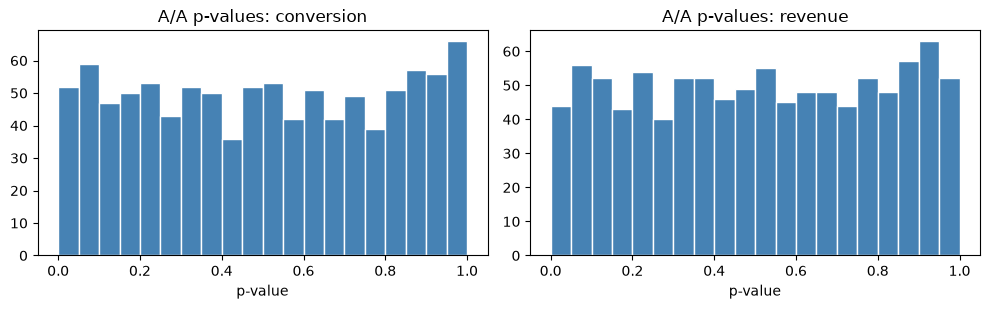

In [7]:
pre_balance = []
for metric in ["orders_pre_56d", "revenue_pre_56d"]:
    a = data.loc[data["is_treatment"] == 0, metric]
    b = data.loc[data["is_treatment"] == 1, metric]
    pre_balance.append({"metric": metric, "control_mean": a.mean(), "treatment_mean": b.mean(),
                        "p_value": stats.ttest_ind(b, a, equal_var=False).pvalue})
print(pd.DataFrame(pre_balance).round(4).to_string(index=False))


def aa_test(df: pd.DataFrame, n_runs: int = 1000, seed: int = 0) -> pd.DataFrame:
    """Repeatedly split the control group in two random halves and record the p-values."""
    rng = np.random.default_rng(seed)
    control = df[df["is_treatment"] == 0]
    conv, rev = control["converted"].values, control["revenue_14d"].values
    p_conv, p_rev = [], []
    for _ in range(n_runs):
        fake = rng.random(len(control)) < 0.5                               # random fake "treatment"
        counts = [conv[fake].sum(), conv[~fake].sum()]
        p_conv.append(proportions_ztest(counts, [fake.sum(), (~fake).sum()])[1])
        p_rev.append(stats.ttest_ind(rev[fake], rev[~fake], equal_var=False).pvalue)
    return pd.DataFrame({"conversion": p_conv, "revenue": p_rev})


aa = aa_test(data)
print("\nA/A false-positive rate (should be close to 5%):")
print((aa < PLAN.alpha).mean().round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col in zip(axes, aa.columns):
    ax.hist(aa[col], bins=20, range=(0, 1), color="steelblue", edgecolor="white")
    ax.set_title(f"A/A p-values: {col}"); ax.set_xlabel("p-value")
plt.tight_layout(); plt.show()

Pre-period means are balanced and the A/A false-positive rates are close to the expected 5% (with 1,000 runs, anything roughly between 3.5% and 6.5% is consistent with 5%; with only a few hundred runs the rate can easily look like 8% or 9% by pure chance). The histograms are roughly flat. Our pipeline is trustworthy, so now we may look at the treatment effect.

---
## 7. Primary metric: conversion

We report three things, always together:
1. the **absolute difference** in conversion (percentage points) with a 95% **confidence interval**;
2. the **relative lift** (what the business usually quotes);
3. the **p-value** of a two-proportion z-test.

A confidence interval is more useful than a p-value alone: it shows the range of effects that are consistent with the data, including how small the effect *could* be.

In [8]:
def conversion_analysis(df: pd.DataFrame) -> dict:
    """Two-proportion z-test + 95% CI for the difference and the relative lift."""
    t, c = df[df["is_treatment"] == 1], df[df["is_treatment"] == 0]
    counts, nobs = np.array([t["converted"].sum(), c["converted"].sum()]), np.array([len(t), len(c)])
    z, p_value = proportions_ztest(counts, nobs)
    low, high = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1], method="wald")
    rate_t, rate_c = counts / nobs
    return {"rate_control": rate_c, "rate_treatment": rate_t, "abs_diff": rate_t - rate_c,
            "ci_low": low, "ci_high": high, "rel_lift": rate_t / rate_c - 1,
            "rel_ci_low": low / rate_c, "rel_ci_high": high / rate_c, "p_value": p_value,
            "n_control": int(nobs[1]), "n_treatment": int(nobs[0])}


primary = conversion_analysis(data)
print(f"Conversion: control {primary['rate_control']:.3%} | treatment {primary['rate_treatment']:.3%}")
print(f"Absolute diff: {primary['abs_diff']:+.3%} (95% CI {primary['ci_low']:+.3%} to {primary['ci_high']:+.3%})")
print(f"Relative lift: {primary['rel_lift']:+.1%} (95% CI {primary['rel_ci_low']:+.1%} to {primary['rel_ci_high']:+.1%})")
print(f"p-value: {primary['p_value']:.2e}")

Conversion: control 6.924% | treatment 7.533%
Absolute diff: +0.609% (95% CI +0.367% to +0.851%)
Relative lift: +8.8% (95% CI +5.3% to +12.3%)
p-value: 7.93e-07


---
## 8. Revenue per user: heavy tails, Welch's t-test and the bootstrap

Revenue per user is the metric finance cares about, and it is statistically nasty: most users spend $0 and a handful of "whales" spend thousands. Let's look before we test.

Share of users with $0 revenue: 92.8%
Mean $6.75 | median $0.00 | 99th pct $161 | max $2,173
The top 0.1% of users bring 10.0% of all revenue


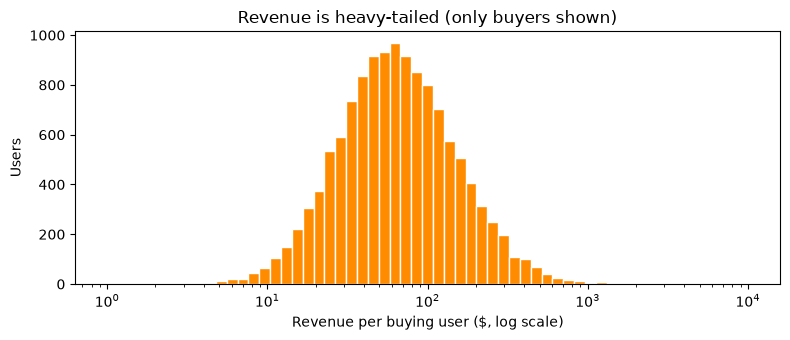

In [9]:
rev = data["revenue_14d"]
print(f"Share of users with $0 revenue: {(rev == 0).mean():.1%}")
print(f"Mean ${rev.mean():.2f} | median ${rev.median():.2f} | 99th pct ${rev.quantile(0.99):,.0f} | max ${rev.max():,.0f}")
top_share = rev.sort_values(ascending=False).head(int(0.001 * len(rev))).sum() / rev.sum()
print(f"The top 0.1% of users bring {top_share:.1%} of all revenue")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rev[rev > 0], bins=np.logspace(0, 4, 60), color="darkorange", edgecolor="white")
ax.set_xscale("log"); ax.set_xlabel("Revenue per buying user ($, log scale)"); ax.set_ylabel("Users")
ax.set_title("Revenue is heavy-tailed (only buyers shown)")
plt.tight_layout(); plt.show()

Three tools that experimentation teams use for such metrics:

1. **Welch's t-test** compares means without assuming equal variances. Thanks to the central limit theorem it works on skewed data **when the sample is large** (we have ~75,000 users per group, and the A/A test above confirmed its false-positive rate is fine).
2. **Bootstrap confidence interval:** re-sample users with replacement many times, recompute the difference each time, and take the 2.5th and 97.5th percentiles. No distribution assumption at all, and it works for any statistic (relative lift, median, ...).
3. **Winsorizing (capping)** as a robustness check: cap each user's revenue at the 99.9th percentile so that one whale can't decide the experiment. If capped and uncapped results disagree, the result depends on a few people: be careful.

In [10]:
def welch_diff(a: np.ndarray, b: np.ndarray, alpha: float = PLAN.alpha) -> dict:
    """Difference in means (b - a) with Welch's t-test and its confidence interval."""
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    test = stats.ttest_ind(b, a, equal_var=False)
    z = stats.norm.ppf(1 - alpha / 2)
    return {"diff": diff, "ci_low": diff - z * se, "ci_high": diff + z * se, "p_value": test.pvalue, "se": se}


def bootstrap_diff(a: np.ndarray, b: np.ndarray, n_boot: int = 1000, seed: int = 0) -> dict:
    """Bootstrap CI for the difference in means and for the relative lift."""
    rng = np.random.default_rng(seed)
    diffs, lifts = np.empty(n_boot), np.empty(n_boot)
    for i in range(n_boot):
        ma = a[rng.integers(0, len(a), len(a))].mean()            # re-sample control users
        mb = b[rng.integers(0, len(b), len(b))].mean()            # re-sample treatment users
        diffs[i], lifts[i] = mb - ma, mb / ma - 1
    return {"diff_ci": np.percentile(diffs, [2.5, 97.5]), "lift_ci": np.percentile(lifts, [2.5, 97.5])}


rev_c = data.loc[data["is_treatment"] == 0, "revenue_14d"].values
rev_t = data.loc[data["is_treatment"] == 1, "revenue_14d"].values
cap = np.quantile(np.r_[rev_c, rev_t], 0.999)                      # winsorizing threshold, pooled

welch = welch_diff(rev_c, rev_t)
boot = bootstrap_diff(rev_c, rev_t)
welch_capped = welch_diff(np.minimum(rev_c, cap), np.minimum(rev_t, cap))
revenue_table = pd.DataFrame([
    {"method": "Welch t-test", "diff_$": welch["diff"], "ci_low": welch["ci_low"], "ci_high": welch["ci_high"],
     "p_value": welch["p_value"]},
    {"method": "Bootstrap (1,000 resamples)", "diff_$": welch["diff"], "ci_low": boot["diff_ci"][0],
     "ci_high": boot["diff_ci"][1], "p_value": np.nan},
    {"method": f"Welch, capped at ${cap:,.0f}", "diff_$": welch_capped["diff"], "ci_low": welch_capped["ci_low"],
     "ci_high": welch_capped["ci_high"], "p_value": welch_capped["p_value"]},
]).set_index("method").round(4)
print(f"Revenue per user: control ${rev_c.mean():.3f} | treatment ${rev_t.mean():.3f} "
      f"| relative lift {rev_t.mean() / rev_c.mean() - 1:+.1%} "
      f"(bootstrap 95% CI {boot['lift_ci'][0]:+.1%} to {boot['lift_ci'][1]:+.1%})")
revenue_table

Revenue per user: control $6.495 | treatment $6.996 | relative lift +7.7% (bootstrap 95% CI +2.3% to +13.3%)


,diff_$,ci_low,ci_high,p_value
method,,,,
Welch t-test,0.5004,0.1542,0.8466,0.0046
"Bootstrap (1,000 resamples)",0.5004,0.1514,0.8427,NaN
"Welch, capped at $448",0.4658,0.1626,0.7690,0.0026


Welch and bootstrap intervals are very close (as expected with this many users), and capping the whales changes the picture only slightly. Notice that the revenue interval is **much wider in relative terms** than the conversion interval: revenue is a noisier metric. That is the reason conversion was chosen as the *primary* metric, and the reason the next section exists.

---
## 9. CUPED: shrink the noise with pre-experiment data

**CUPED** (Controlled-experiment Using Pre-Experiment Data, Deng et al., Microsoft 2013) is used by almost every big experimentation platform. The idea:

> Part of why users differ in revenue has nothing to do with the experiment: heavy buyers were heavy buyers *before* the test too. If we subtract the part of the metric that is predictable from the **pre-period**, the remaining noise is smaller, and the confidence interval gets narrower **without collecting more users**.

The recipe for each user:

`Y_cuped = Y − θ · (X − mean(X))`,  with `θ = cov(X, Y) / var(X)`

where `Y` is revenue during the test and `X` is revenue in the 8 weeks before. Because `X` was measured **before** randomization, it is independent of the treatment, so the adjustment does not bias the estimate; it only removes noise. (Never use a covariate that the treatment could affect!)

In [11]:
def cuped_adjust(y: np.ndarray, x: np.ndarray) -> tuple[np.ndarray, float]:
    """Return the CUPED-adjusted metric and theta. x must be a PRE-experiment covariate."""
    theta = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), theta


cuped_rows = []
for metric, covariate in [("revenue_14d", "revenue_pre_56d"), ("converted", "orders_pre_56d")]:
    y = data[metric].values.astype(float)
    x = data[covariate].values.astype(float)
    y_adj, theta = cuped_adjust(y, x)                                # theta estimated on BOTH groups pooled
    t = data["is_treatment"].values == 1
    raw_res, adj_res = welch_diff(y[~t], y[t]), welch_diff(y_adj[~t], y_adj[t])
    cuped_rows.append({
        "metric": metric, "covariate": covariate, "theta": round(theta, 4),
        "corr(X, Y)": round(np.corrcoef(x, y)[0, 1], 3),
        "variance_reduction": f"{1 - y_adj.var() / y.var():.1%}",
        "diff_raw": raw_res["diff"], "ci_width_raw": raw_res["ci_high"] - raw_res["ci_low"], "p_raw": raw_res["p_value"],
        "diff_cuped": adj_res["diff"], "ci_width_cuped": adj_res["ci_high"] - adj_res["ci_low"], "p_cuped": adj_res["p_value"],
        "equivalent_extra_users": f"{y.var() / y_adj.var() - 1:+.0%}",
    })
cuped_table = pd.DataFrame(cuped_rows).set_index("metric")
cuped_table.T

metric,revenue_14d,converted
covariate,revenue_pre_56d,orders_pre_56d
theta,0.1764,0.076
"corr(X, Y)",0.412,0.28
variance_reduction,17.0%,7.9%
diff_raw,0.500435,0.006092
ci_width_raw,0.692411,0.004837
p_raw,0.00461,0.000001
diff_cuped,0.531883,0.005998
ci_width_cuped,0.630861,0.004643
p_cuped,0.00095,0.0


How to read the table:
- **variance_reduction** = how much noise CUPED removed. The variance falls by about **1 − corr²**, so a stronger correlation between before and after gives a bigger gain.
- **equivalent_extra_users** = the same precision would have needed this many more users without CUPED. That is free statistical power, or an experiment that could be stopped earlier.
- The effect estimate itself (`diff_cuped`) stays close to the raw one; only the **interval** gets narrower.

Be honest about the size of the gain: for **revenue** the pre-period is informative and the gain is clear. For **conversion** (a rare yes/no event) the past predicts the future less well, so the reduction is smaller. That is typical in practice: CUPED helps most for metrics where users are consistent over time (revenue, sessions, minutes watched). New users have no pre-period at all (X = 0 for them), which also limits the gain.

---
## 10. Guardrail metrics

A checkout that sells more but makes the site slower or causes payment failures is not a win. Guardrails are checked as **non-inferiority**: the upper end of the 95% CI of (treatment − control) must stay below the limit we wrote into the plan.

In [12]:
data["payment_error_rate"] = data["payment_errors"] / data["payment_attempts"].where(data["payment_attempts"] > 0)
GUARDRAILS = {"page_load_ms": "page_load_ms", "payment_error_rate": "payment_error_rate",
              "support_contacts_per_user": "support_contacts"}

guard_rows = []
for name, column in GUARDRAILS.items():
    values = data[[column, "is_treatment"]].dropna()                  # error rate only exists for users who paid
    res = welch_diff(values.loc[values["is_treatment"] == 0, column].values,
                     values.loc[values["is_treatment"] == 1, column].values)
    limit = PLAN.guardrail_limits[name]
    guard_rows.append({"guardrail": name, "control": values.loc[values["is_treatment"] == 0, column].mean(),
                       "treatment": values.loc[values["is_treatment"] == 1, column].mean(),
                       "diff": res["diff"], "ci_high": res["ci_high"], "limit": limit,
                       "status": "PASS" if res["ci_high"] < limit else "FAIL"})
guardrails = pd.DataFrame(guard_rows).set_index("guardrail")
guardrails.round(5)

,control,treatment,diff,ci_high,limit,status
guardrail,,,,,,
page_load_ms,1914.88027,1958.02294,43.14267,49.59744,100.000,PASS
payment_error_rate,0.01912,0.01879,-0.00033,0.00355,0.005,PASS
support_contacts_per_user,0.03169,0.02979,-0.00190,-0.00026,0.005,PASS


The new checkout **is** measurably slower (the difference in page load time is clearly above zero), but the whole confidence interval stays below the +100 ms the team accepted, so the guardrail passes. This is a typical real-world outcome: "statistically significant" and "practically important" are different questions, and the guardrail limit is the business's answer to the second one. Payment errors show no meaningful change. Support contacts even look slightly **lower** in the treatment group, with a confidence interval that excludes zero. Careful: our simulator gave both groups exactly the same support-contact rate, so this is a **chance finding**. With several metrics, one of them will sometimes look "significant" by luck; that is the multiple-testing problem of the next section, and the reason guardrails are only used to *block* a launch, never to claim extra wins.

---
## 11. Segment analysis with multiple-testing correction

Stakeholders always ask: *"Does it work for mobile? For new users? In Germany?"* Segment results are useful to **understand** an effect, but dangerous for **decisions**: if you test 10 segments at alpha = 0.05, the chance of at least one false positive is about 40% even when nothing is going on.

So we correct the p-values:
- **Holm** controls the chance of *any* false positive (strict, family-wise error rate);
- **Benjamini-Hochberg (BH)** controls the expected *share* of false discoveries (FDR, less strict, popular for exploration).

In [13]:
segment_rows = []
for dimension in ["device", "user_type", "country"]:
    for level, group in data.groupby(dimension):
        res = conversion_analysis(group)
        segment_rows.append({"segment": f"{dimension}={level}", "users": len(group),
                             "rate_control": res["rate_control"], "rel_lift": res["rel_lift"],
                             "rel_ci": f"{res['rel_ci_low']:+.1%} to {res['rel_ci_high']:+.1%}",
                             "p_value": res["p_value"]})
segments = pd.DataFrame(segment_rows).set_index("segment")
segments["p_holm"] = multipletests(segments["p_value"], method="holm")[1]
segments["p_bh"] = multipletests(segments["p_value"], method="fdr_bh")[1]
segments["significant_after_BH"] = segments["p_bh"] < PLAN.alpha
segments.round({"rate_control": 4, "rel_lift": 3, "p_value": 4, "p_holm": 4, "p_bh": 4})

,users,rate_control,rel_lift,rel_ci,p_value,p_holm,p_bh,significant_after_BH
segment,,,,,,,,
device=desktop,61729,0.0851,0.030,-2.2% to +8.2%,0.2657,0.3843,0.2657,False
device=mobile,96728,0.0595,0.135,+8.3% to +18.6%,0.0000,0.0000,0.0000,True
device=tablet,17731,0.0669,0.116,+0.4% to +22.9%,0.0432,0.1749,0.0617,False
user_type=new,52788,0.0500,0.150,+7.3% to +22.6%,0.0001,0.0012,0.0005,True
user_type=returning,123400,0.0774,0.071,+3.2% to +11.0%,0.0004,0.0025,0.0009,True
country=CA,17481,0.0725,0.084,-2.4% to +19.2%,0.1281,0.3843,0.1601,False
country=DE,26274,0.0713,0.064,-2.4% to +15.3%,0.1545,0.3843,0.1717,False
country=FR,26369,0.0643,0.187,+9.1% to +28.3%,0.0001,0.0012,0.0005,True
country=UK,35368,0.0692,0.084,+0.6% to +16.2%,0.0350,0.1749,0.0583,False


"Significant in mobile but not in desktop" does **not** prove that the effect is *different* between the two (a classic mistake: the desktop segment may just be too small to detect its effect). To claim a difference, test the **difference of the effects** directly (an *interaction* test):

In [14]:
def effect_difference(df_a: pd.DataFrame, df_b: pd.DataFrame) -> dict:
    # z-test for (absolute lift in segment a) minus (absolute lift in segment b)
    ra, rb = conversion_analysis(df_a), conversion_analysis(df_b)
    se_a = (ra["ci_high"] - ra["ci_low"]) / (2 * 1.96)          # standard error recovered from each CI
    se_b = (rb["ci_high"] - rb["ci_low"]) / (2 * 1.96)
    diff = ra["abs_diff"] - rb["abs_diff"]
    z = diff / np.sqrt(se_a ** 2 + se_b ** 2)
    return {"lift_a_pp": ra["abs_diff"] * 100, "lift_b_pp": rb["abs_diff"] * 100,
            "difference_pp": diff * 100, "p_value": 2 * stats.norm.sf(abs(z))}


interaction = effect_difference(data[data["device"] == "mobile"], data[data["device"] == "desktop"])
print("Mobile vs desktop (absolute lift in percentage points):",
      {k: round(float(v), 4) for k, v in interaction.items()})

Mobile vs desktop (absolute lift in percentage points): {'lift_a_pp': 0.8015, 'lift_b_pp': 0.2517, 'difference_pp': 0.5498, 'p_value': 0.0458}


**How to read it:** compare the raw `p_value` with the corrected columns. Some segments that look significant on their own lose significance after the correction; those are the ones you should **not** build a story on. The device split is the clearest pattern: the lift is concentrated on **mobile**, which matches the product hypothesis (the new checkout was designed mobile-first). A sound way to communicate this: *"the overall effect is positive; the effect appears to be driven by mobile; this is a hypothesis for the next experiment, not a separate decision."*

Remember too that each segment has far fewer users than the whole experiment, so its confidence interval is much wider. A segment with "no significant effect" is usually **under-powered**, not proven to be zero.

Here mobile gains about three times as many percentage points as desktop, but the p-value of the *difference* is only borderline (around 0.05). Honest wording: *"evidence suggests the new checkout helps mobile more than desktop; a mobile-specific follow-up test would confirm it"*.

---
## 12. Novelty effect: is the lift fading over time?

When users see something new, they often click around out of curiosity (**novelty effect**); sometimes the opposite happens and they need time to get used to it (**change aversion**). Either way, the **first days are not representative** of the long run.

We split users by the **week** in which they first saw the experiment and estimate the lift per week.

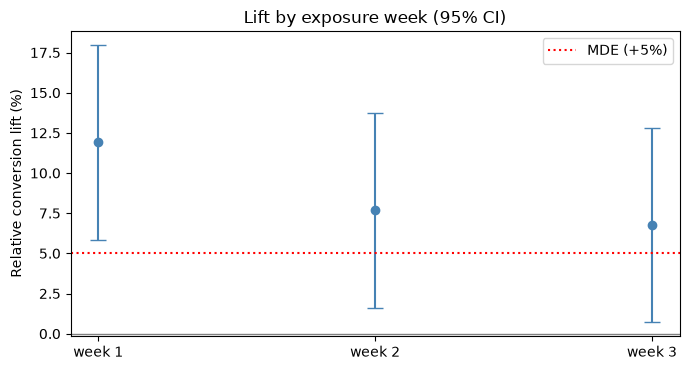

Lift in week 1: +11.9% | weeks 2-3: +7.2% (95% CI +2.9% to +11.5%)


,n_control,n_treatment,rate_control,rel_lift,rel_ci_low,rel_ci_high,p_value
week 1,29435.0,29299.0,0.0701,0.1191,0.0586,0.1796,0.0001
week 2,29241.0,29491.0,0.0688,0.0767,0.0162,0.1373,0.0130
week 3,29464.0,29258.0,0.0688,0.0677,0.0072,0.1281,0.0282


In [15]:
data["exposure_week"] = data["exposure_day"] // 7 + 1
weekly = pd.DataFrame({f"week {w}": conversion_analysis(g) for w, g in data.groupby("exposure_week")}).T
weekly = weekly[["n_control", "n_treatment", "rate_control", "rel_lift", "rel_ci_low", "rel_ci_high", "p_value"]]

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(weekly))
ax.errorbar(x, weekly["rel_lift"] * 100,
            yerr=[(weekly["rel_lift"] - weekly["rel_ci_low"]) * 100, (weekly["rel_ci_high"] - weekly["rel_lift"]) * 100],
            fmt="o", capsize=6, color="steelblue")
ax.axhline(0, color="grey", lw=1); ax.axhline(PLAN.mde_relative * 100, color="red", ls=":", label="MDE (+5%)")
ax.set_xticks(x, weekly.index); ax.set_ylabel("Relative conversion lift (%)")
ax.set_title("Lift by exposure week (95% CI)"); ax.legend(); plt.tight_layout(); plt.show()

late = conversion_analysis(data[data["exposure_week"] >= 2])           # weeks 2-3: closer to the long run
print(f"Lift in week 1: {weekly['rel_lift'].iloc[0]:+.1%} | weeks 2-3: {late['rel_lift']:+.1%} "
      f"(95% CI {late['rel_ci_low']:+.1%} to {late['rel_ci_high']:+.1%})")
weekly.astype(float).round(4)

The first week shows a larger lift than the later weeks: a **novelty effect**. The weekly intervals are wide (each week has only a third of the users), so we should not over-interpret one point, but the direction is consistent with "the excitement wears off". For the business case we therefore use the **weeks 2-3** estimate as the more realistic long-run lift, not the headline number over all three weeks.

> **Industry practice:** large companies keep a small **long-term holdout** (e.g. 1-5% of users who keep the old checkout for months) to measure the effect after the novelty has completely worn off.

---
## 13. The decision memo (generated from the results)

The final deliverable of an experiment is not a notebook, it is a **one-page memo** that a product manager can read in two minutes. We generate it **from the computed results**, so the numbers in the memo can never drift from the analysis.

The decision rules (also part of the pre-registered plan):
1. SRM detected → **INVALID**, fix and re-run.
2. Any guardrail fails → **DO NOT SHIP**.
3. Primary metric CI entirely above 0 → **SHIP**, but use the long-run (weeks 2-3) estimate for planning. If that estimate is below the MDE, flag that the benefit may be smaller than hoped.
4. Primary metric CI entirely below 0 → **DO NOT SHIP**.
5. Otherwise → **NO DETECTABLE EFFECT**: keep the old version, or ship only for non-metric reasons.

In [16]:
def decide(srm: dict, primary: dict, guardrails: pd.DataFrame, late: dict) -> tuple[str, list[str]]:
    """Apply the pre-registered decision rules. Returns (decision, list of reasons)."""
    reasons = []
    if srm["srm_detected"]:
        return "INVALID - investigate sample ratio mismatch", ["SRM p-value below 0.001"]
    failed = guardrails.index[guardrails["status"] == "FAIL"].tolist()
    if failed:
        return "DO NOT SHIP", [f"guardrail failed: {g}" for g in failed]
    if primary["ci_low"] > 0:
        reasons.append("primary metric improved with 95% confidence")
        if late["rel_lift"] < PLAN.mde_relative:
            reasons.append(f"long-run lift estimate ({late['rel_lift']:+.1%}) is below the {PLAN.mde_relative:.0%} MDE")
        return "SHIP", reasons
    if primary["ci_high"] < 0:
        return "DO NOT SHIP", ["primary metric got worse"]
    return "NO DETECTABLE EFFECT", ["confidence interval includes zero"]


srm_overall = srm_check(data)
decision, reasons = decide(srm_overall, primary, guardrails, late)

yearly_users = PLAN.daily_users * 365
rev_ci = boot["diff_ci"]
sig_segments = segments.index[segments["significant_after_BH"]].tolist()

memo = f"""
==========================================================================================
EXPERIMENT DECISION MEMO: {PLAN.experiment_id}                generated {datetime.now():%Y-%m-%d}
==========================================================================================
DECISION: {decision}
  Why: {'; '.join(reasons)}

WHAT WE TESTED
  New one-page checkout vs current checkout, 50/50 split, {weeks_planned} weeks,
  {primary['n_control'] + primary['n_treatment']:,} users after cleaning (bots, duplicates, cross-exposed removed).

TRUSTWORTHINESS
  Sample ratio: {srm_overall['treatment_share']:.2%} treatment (SRM p = {srm_overall['p_value']}) -> OK
  Pre-period balance and A/A false-positive rate ({(aa['conversion'] < PLAN.alpha).mean():.1%}) -> OK

PRIMARY METRIC: conversion (14 days)
  {primary['rate_control']:.2%} -> {primary['rate_treatment']:.2%}  = {primary['rel_lift']:+.1%} relative
  95% CI {primary['rel_ci_low']:+.1%} to {primary['rel_ci_high']:+.1%}, p = {primary['p_value']:.1e}
  Long-run estimate (weeks 2-3, after novelty): {late['rel_lift']:+.1%} (95% CI {late['rel_ci_low']:+.1%} to {late['rel_ci_high']:+.1%})

REVENUE PER USER (secondary)
  ${rev_c.mean():.2f} -> ${rev_t.mean():.2f}, difference ${welch['diff']:+.3f} (bootstrap 95% CI ${rev_ci[0]:+.3f} to ${rev_ci[1]:+.3f})
  Rough yearly impact at {yearly_users:,} cart users/year: ${welch['diff'] * yearly_users:+,.0f}
  (range ${rev_ci[0] * yearly_users:+,.0f} to ${rev_ci[1] * yearly_users:+,.0f}; whole period incl. novelty, so likely optimistic)
  CUPED on pre-period revenue reduced variance by {cuped_table.loc['revenue_14d', 'variance_reduction']}.

GUARDRAILS (upper 95% bound must stay below the limit)
""" + "\n".join(f"  {g:28s} diff {r['diff']:+.4f}  upper {r['ci_high']:+.4f}  limit {r['limit']:+.4f}  {r['status']}"
                for g, r in guardrails.iterrows()) + f"""

SEGMENTS (Benjamini-Hochberg corrected): significant in {', '.join(sig_segments) or 'none'}
  Treat segment results as hypotheses for follow-up tests, not as separate decisions.

RISKS / NEXT STEPS
  - Novelty: week-1 lift {weekly['rel_lift'].iloc[0]:+.1%} vs weeks 2-3 {late['rel_lift']:+.1%}; keep a 2% long-term holdout for 3 months.
  - Page load is slower but within the agreed limit; ask engineering to optimise the payment scripts.
==========================================================================================
"""
print(memo)


EXPERIMENT DECISION MEMO: checkout_onepage_v2                generated 2026-10-21
DECISION: SHIP
  Why: primary metric improved with 95% confidence

WHAT WE TESTED
  New one-page checkout vs current checkout, 50/50 split, 3 weeks,
  176,188 users after cleaning (bots, duplicates, cross-exposed removed).

TRUSTWORTHINESS
  Sample ratio: 49.97% treatment (SRM p = 0.8265) -> OK
  Pre-period balance and A/A false-positive rate (5.2%) -> OK

PRIMARY METRIC: conversion (14 days)
  6.92% -> 7.53%  = +8.8% relative
  95% CI +5.3% to +12.3%, p = 7.9e-07
  Long-run estimate (weeks 2-3, after novelty): +7.2% (95% CI +2.9% to +11.5%)

REVENUE PER USER (secondary)
  $6.50 -> $7.00, difference $+0.500 (bootstrap 95% CI $+0.151 to $+0.843)
  Rough yearly impact at 3,102,500 cart users/year: $+1,552,598
  (range $+469,798 to $+2,614,543; whole period incl. novelty, so likely optimistic)
  CUPED on pre-period revenue reduced variance by 17.0%.

GUARDRAILS (upper 95% bound must stay below the limit)
  

---
## 14. Save the analysis for the experiment registry

Companies keep a searchable **registry of all experiments** with their plan, results and decision, so that six months later nobody re-runs the same test, and so meta-analyses ("how often do checkout changes win?") are possible. We save the plan, the results and the memo as JSON. In a real project this would go to a database table or a wiki page; here it goes to a temporary folder.

In [17]:
OUT_DIR = Path(tempfile.mkdtemp(prefix="ab_report_"))      # real project: experiment registry / database


def to_jsonable(obj):
    """Convert numpy / pandas values into plain Python types for JSON."""
    if isinstance(obj, dict):
        return {k: to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, np.ndarray)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer, np.floating, np.bool_)):
        return obj.item()
    return obj


record = to_jsonable({
    "experiment_id": PLAN.experiment_id, "analysed_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "plan": asdict(PLAN), "decision": decision, "reasons": reasons, "srm": srm_overall,
    "primary_conversion": primary, "late_period_conversion": late,
    "revenue": {"welch": welch, "bootstrap_ci": boot["diff_ci"]},
    "guardrails": guardrails.reset_index().to_dict(orient="records"),
    "segments": segments.reset_index().to_dict(orient="records"),
})
(OUT_DIR / "results.json").write_text(json.dumps(record, indent=2, default=str))
(OUT_DIR / "memo.txt").write_text(memo)
for f in OUT_DIR.iterdir():
    print(f"{f.name:14s} {f.stat().st_size / 1024:6.1f} KB")

results.json      5.9 KB
memo.txt          1.9 KB


---
## 15. Automated sanity tests

The analysis code is re-used for every experiment, so it deserves tests like any other software (see `../../15_MLOps/07_testing_in_ml/`). The most valuable test in experimentation: **simulate an experiment where we know the answer** and check that the pipeline finds it. With no true effect, it must not claim a win; with a broken split, the SRM check must fire.

In [18]:
def test_srm_detects_broken_split():
    assert srm_check(buggy.groupby("device").get_group("mobile"))["srm_detected"]


def test_no_effect_experiment_is_not_shipped():
    null_data = clean_experiment_data(simulate_experiment(days=7, seed=99, true_effect=False))
    null_data["converted"] = (null_data["orders_14d"] > 0).astype(int)
    null_data["is_treatment"] = (null_data["variant"] == "treatment").astype(int)
    result = conversion_analysis(null_data)
    assert result["ci_low"] <= 0 <= result["ci_high"], "pipeline invented an effect"


def test_cuped_does_not_increase_variance():
    y, x = data["revenue_14d"].values, data["revenue_pre_56d"].values
    assert cuped_adjust(y, x)[0].var() <= y.var()


def test_aa_false_positive_rate_is_reasonable():
    assert (aa < PLAN.alpha).mean().max() < 0.10


def test_memo_numbers_match_results():
    assert f"{primary['rel_lift']:+.1%}" in memo and decision in memo


for test in [test_srm_detects_broken_split, test_no_effect_experiment_is_not_shipped,
             test_cuped_does_not_increase_variance, test_aa_false_positive_rate_is_reasonable,
             test_memo_numbers_match_results]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_srm_detects_broken_split


2026-10-21 16:32:53,283 | INFO | Removed crossed users per variant: {'control': 178, 'treatment': 178}


2026-10-21 16:32:53,286 | INFO | Removed bots per variant: {'control': 300, 'treatment': 292}


PASSED  test_no_effect_experiment_is_not_shipped
PASSED  test_cuped_does_not_increase_variance
PASSED  test_aa_false_positive_rate_is_reasonable
PASSED  test_memo_numbers_match_results


---
## 16. Summary, exercises and resources

| Industry practice | What we did | Where it's used |
|---|---|---|
| Pre-registered plan | Metric, alpha, MDE, guardrail limits fixed in a frozen config | Every mature experimentation team |
| Power analysis | `statsmodels` sample size, rounded up to full weeks | Planning with product managers |
| Cleaning rules | Bots, duplicates, cross-exposed users, balanced removal check | Experiment platforms |
| SRM check | Chi-square overall and per device; demo of a real bug | Microsoft, LinkedIn, Booking, ... (automatic alert) |
| A/A test | Our pipeline's false-positive rate ≈ 5% | Validating new metrics and platforms |
| Heavy-tailed metrics | Welch t-test, bootstrap CI, winsorizing check | Revenue, order value, time spent |
| CUPED | Pre-period covariate, variance reduction | Microsoft ExP, Netflix, Airbnb, Statsig, Eppo |
| Guardrails | Non-inferiority on upper CI bound | Performance, errors, support load |
| Segments | Holm / Benjamini-Hochberg correction | Exploratory analysis |
| Novelty | Lift by exposure week, long-run estimate | Long-term holdouts |
| Decision memo | Generated from results with explicit rules | Product reviews |

### Practice exercises
1. Change `mde_relative` to 0.03. How many weeks would the experiment need?
2. Re-run the analysis on `buggy` instead of `data`. What does the memo say?
3. Use **both** `revenue_pre_56d` and `orders_pre_56d` as CUPED covariates (fit a linear regression of Y on X1, X2 and use the residual). Is the variance reduction larger?
4. Add a fourth guardrail, "share of users with a refund", to the simulator and the plan.
5. Implement the **delta method** CI for the relative lift and compare it with the bootstrap CI.

### Resources (checked)
- Kohavi, Tang, Xu: *Trustworthy Online Controlled Experiments* (the standard book): https://experimentguide.com/
- Fabijan et al., *Diagnosing Sample Ratio Mismatch in Online Controlled Experiments* (KDD 2019): https://www.microsoft.com/en-us/research/?p=651990 and the SRM taxonomy https://lukasvermeer.nl/srm/docs/causes/
- Deng, Xu, Kohavi, Walker: *Improving the Sensitivity of Online Controlled Experiments by Utilizing Pre-Experiment Data* (CUPED, WSDM 2013): https://exp-platform.com/Documents/2013-02-CUPED-ImprovingSensitivityOfControlledExperiments.pdf
- Ambrosia (open-source A/B library) CUPED examples: https://ambrosia.readthedocs.io/en/latest/pandas_examples/01_vr_transformations.html
- statsmodels power and proportion tests: https://www.statsmodels.org/stable/stats.html#power-and-sample-size-calculations

### Related notebooks in this repo
- Theory: `01_ab_testing.ipynb` (z-test from scratch, peeking, Bayesian A/B, bandits)
- Causal effects for individuals (who benefits?): `../10_causal_inference/01_causal_inference.ipynb`
- Statistics refresher: `../../02_Data_Analysis/08_statistics.ipynb`
- Monitoring models after launch: `../../15_MLOps/06_monitoring/01_monitoring.ipynb`